# Checkpoint 2 Alura · Veículos elétricos

Analisamos o perfil dos veículos registrados na base, comparamos indicadores por ano de fabricação e estimamos o valor de revenda em dólares. A amostra contém veículos de 2015 a 2024. Ela oferece comparações entre grupos e coortes. Medir adoção no mercado exigiria registros ou vendas por período e um denominador, como o total de veículos do mercado.

## 1. Exploração estatística e comparação de grupos

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid")
url = "https://cdn3.gnarususercontent.com.br/5210-projeto-cientista-dados-nivel-2/electric_vehicle_analytics%28in%29.csv"
arquivo = Path("data/electric_vehicle_analytics.csv")
if not arquivo.exists():
    arquivo.parent.mkdir(exist_ok=True)
    urlretrieve(url, arquivo)
bruto = pd.read_csv(arquivo)
alvo = "Resale_Value_USD"
print(f"{bruto.shape[0]:,} linhas, {bruto.shape[1]} colunas, "
      f"{bruto.duplicated().sum()} duplicatas exatas e "
      f"{bruto.Vehicle_ID.duplicated().sum()} IDs repetidos.")
display(pd.DataFrame({"tipo": bruto.dtypes, "nulos": bruto.isna().sum(),
                      "distintos": bruto.nunique()}))
dados = bruto.drop_duplicates().dropna(subset=[alvo]).copy()
assert dados.Vehicle_ID.is_unique
numericas = dados.select_dtypes(include="number").drop(columns="Vehicle_ID")
categoricas = dados.select_dtypes(exclude="number").columns
display(numericas.describe().T.round(2))
display(dados[categoricas].describe().T)

3,000 linhas, 25 colunas, 0 duplicatas exatas e 0 IDs repetidos.


,tipo,nulos,distintos
Vehicle_ID,int64,0,3000
Make,object,0,10
Model,object,0,23
Year,int64,0,10
Region,object,0,4
Vehicle_Type,object,0,4
Battery_Capacity_kWh,float64,0,878
Battery_Health_%,float64,0,301
Range_km,int64,0,547
Charging_Power_kW,float64,0,1708


,count,mean,std,min,25%,50%,75%,max
Year,3000.0,2019.50,2.85,2015.00,2017.00,2020.00,2022.00,2024.00
Battery_Capacity_kWh,3000.0,74.81,25.73,30.00,53.00,74.85,96.90,120.00
Battery_Health_%,3000.0,85.03,8.59,70.00,77.78,85.25,92.30,100.00
Range_km,3000.0,374.41,137.18,121.00,260.00,371.00,476.25,713.00
Charging_Power_kW,3000.0,129.30,68.74,11.10,70.90,126.70,187.98,250.00
Charging_Time_hr,3000.0,1.20,1.42,0.14,0.46,0.72,1.29,12.14
Charge_Cycles,3000.0,1107.01,510.83,200.00,674.75,1116.00,1535.25,1997.00
Energy_Consumption_kWh_per_100km,3000.0,18.59,3.77,12.00,15.32,18.70,21.83,24.99
Mileage_km,3000.0,125209.69,70465.77,5046.00,65140.50,125965.00,184764.75,249987.00
Avg_Speed_kmh,3000.0,65.67,20.31,30.00,48.00,65.60,83.52,100.00


,count,unique,top,freq
Make,3000,10,Ford,323
Model,3000,23,Niro EV,163
Region,3000,4,Australia,794
Vehicle_Type,3000,4,Hatchback,773
Usage_Type,3000,3,Personal,1020


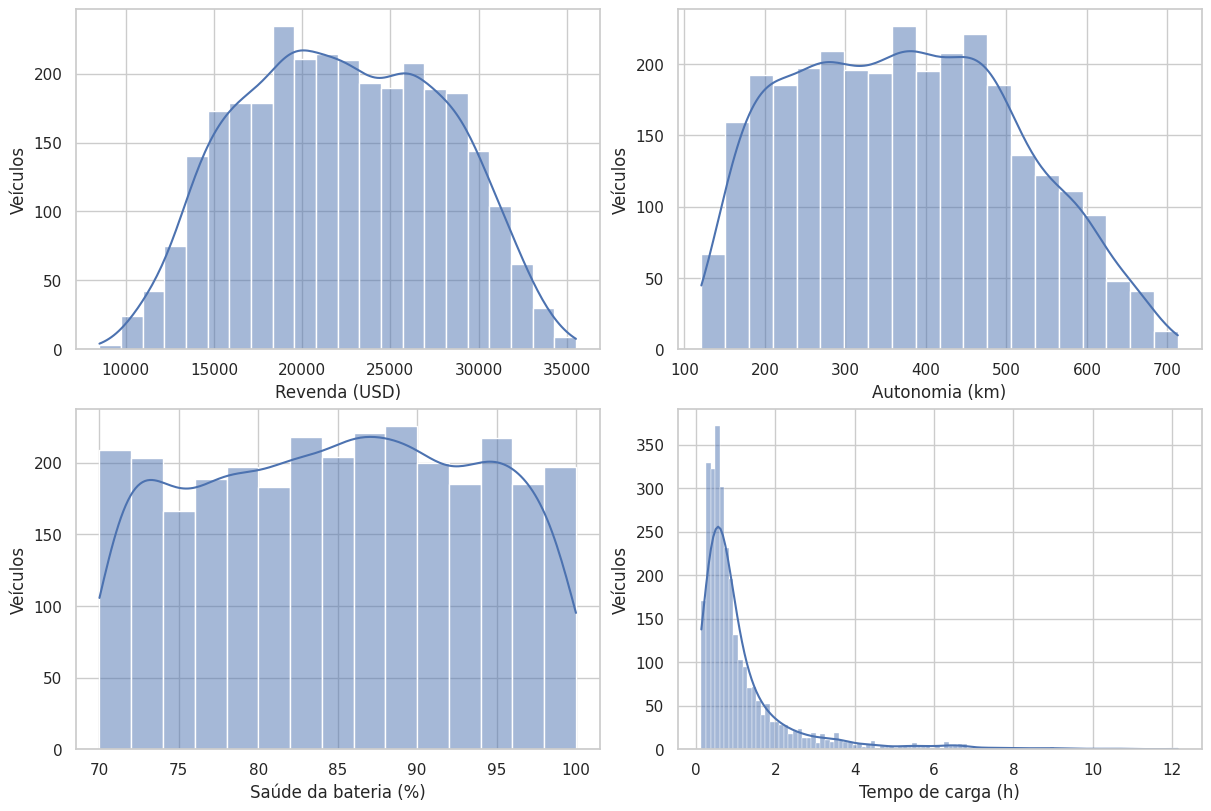

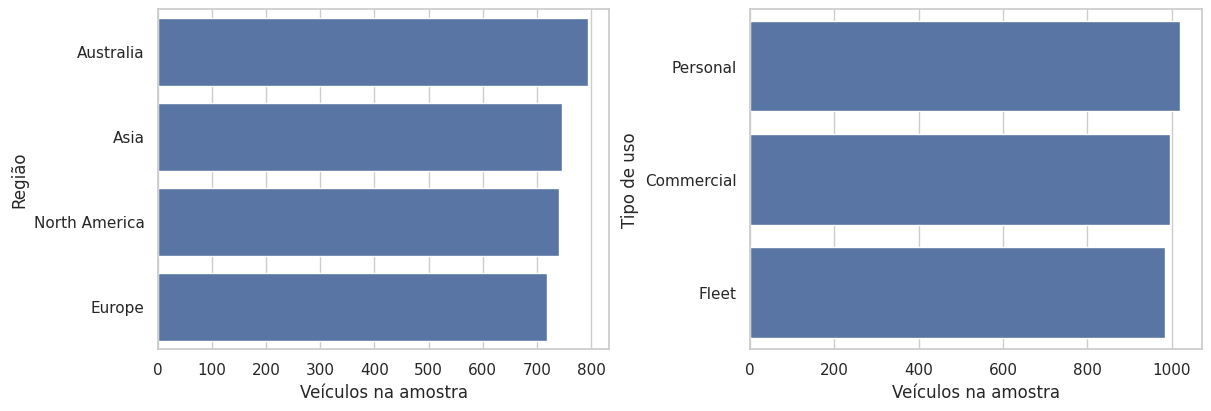

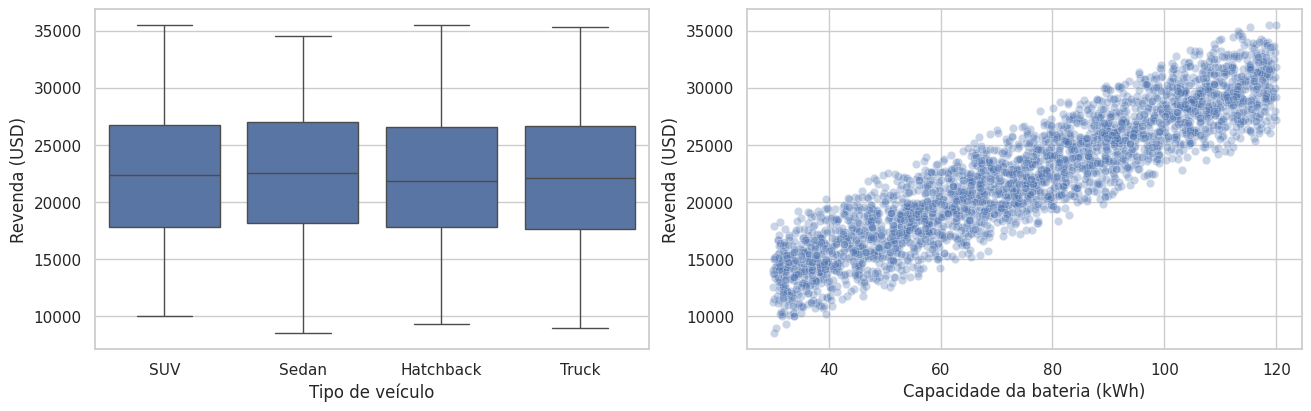

,size,median,mean
Vehicle_Type,,,
Hatchback,773,21832.0,22120.83
SUV,765,22325.0,22324.61
Sedan,738,22508.5,22356.47
Truck,724,22126.5,22229.71


,size,median,mean
Usage_Type,,,
Commercial,996,0.69,1.17
Fleet,984,0.74,1.22
Personal,1020,0.73,1.23


In [2]:
fig, eixos = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, coluna, rotulo in zip(
    eixos.flat, [alvo, "Range_km", "Battery_Health_%", "Charging_Time_hr"],
    ["Revenda (USD)", "Autonomia (km)", "Saúde da bateria (%)", "Tempo de carga (h)"],
):
    sns.histplot(dados[coluna], kde=True, ax=ax)
    ax.set(xlabel=rotulo, ylabel="Veículos")
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for coluna, ax in zip(["Region", "Usage_Type"], eixos):
    sns.countplot(data=dados, y=coluna, order=dados[coluna].value_counts().index, ax=ax)
    ax.set(xlabel="Veículos na amostra", ylabel={"Region": "Região", "Usage_Type": "Tipo de uso"}[coluna])
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
sns.boxplot(data=dados, x="Vehicle_Type", y=alvo, ax=eixos[0])
eixos[0].set(xlabel="Tipo de veículo", ylabel="Revenda (USD)")
sns.scatterplot(data=dados, x="Battery_Capacity_kWh", y=alvo, alpha=.3, ax=eixos[1])
eixos[1].set(xlabel="Capacidade da bateria (kWh)", ylabel="Revenda (USD)")
plt.show()

display(dados.groupby("Vehicle_Type")[alvo].agg(["size", "median", "mean"]).round(2))
display(dados.groupby("Usage_Type")["Charging_Time_hr"].agg(["size", "median", "mean"]).round(2))

Selecionamos quatro comparações exploratórias. Kruskal–Wallis compara as distribuições por grupos independentes usando postos. Reportamos eta quadrado baseado em H como tamanho de efeito, truncado em zero. Spearman mede associação monotônica. Usamos correção de Holm para os quatro testes e nível de 5%. A inferência depende da independência das observações e do processo de amostragem.

In [3]:
testes = []
for resposta, grupo in [(alvo, "Vehicle_Type"), ("Charging_Time_hr", "Usage_Type")]:
    amostras = [v.dropna().to_numpy() for _, v in dados.groupby(grupo)[resposta]]
    h, p = stats.kruskal(*amostras)
    k = len(amostras)
    n = sum(map(len, amostras))
    testes.append((f"{resposta} por {grupo}", "Kruskal–Wallis", h, p,
                   max(0, (h - k + 1) / (n - k))))
for coluna in ["Battery_Capacity_kWh", "Mileage_km"]:
    rho, p = stats.spearmanr(dados[coluna], dados[alvo], nan_policy="omit")
    testes.append((f"{coluna} e revenda", "Spearman", rho, p, rho))
tabela = pd.DataFrame(testes, columns=["Comparação", "Teste", "Estatística", "p", "Efeito"])
tabela["p (Holm)"] = multipletests(tabela["p"], method="holm")[1]
def formatar_p(valor):
    return f"{valor:.3g}" if valor > 0 else "abaixo da precisão numérica"

display(tabela.assign(**{coluna: tabela[coluna].map(formatar_p)
                         for coluna in ["p", "p (Holm)"]}).round(3))

for linha in tabela.itertuples(index=False, name=None):
    nome, teste, _, _, efeito, p_ajustado = linha
    medida = "ρ" if teste == "Spearman" else "η²"
    evidencia = "houve evidência estatística de associação ou diferença" if p_ajustado < .05 else "a evidência estatística foi insuficiente ao nível de 5%"
    display(Markdown(f"- **{nome}**. {medida} = {efeito:.3f}, p ajustado = "
                     f"{formatar_p(p_ajustado)}. Nesta comparação, {evidencia}."))

,Comparação,Teste,Estatística,p,Efeito,p (Holm)
0,Resale_Value_USD por Vehicle_Type,Kruskal–Wallis,1.221,0.748,0.000,0.835
1,Charging_Time_hr por Usage_Type,Kruskal–Wallis,2.361,0.307,0.000,0.835
2,Battery_Capacity_kWh e revenda,Spearman,0.921,abaixo da precisão numérica,0.921,abaixo da precisão numérica
3,Mileage_km e revenda,Spearman,-0.020,0.278,-0.020,0.835


- **Resale_Value_USD por Vehicle_Type**. η² = 0.000, p ajustado = 0.835. Nesta comparação, a evidência estatística foi insuficiente ao nível de 5%.

- **Charging_Time_hr por Usage_Type**. η² = 0.000, p ajustado = 0.835. Nesta comparação, a evidência estatística foi insuficiente ao nível de 5%.

- **Battery_Capacity_kWh e revenda**. ρ = 0.921, p ajustado = abaixo da precisão numérica. Nesta comparação, houve evidência estatística de associação ou diferença.

- **Mileage_km e revenda**. ρ = -0.020, p ajustado = 0.835. Nesta comparação, a evidência estatística foi insuficiente ao nível de 5%.

A associação entre capacidade da bateria e revenda é descritiva. Ano, autonomia e características do modelo podem acompanhar essa relação. A avaliação preditiva a seguir considera essas variáveis em conjunto.

## 2. Tendências de Mercado

As linhas abaixo comparam coortes de fabricação em uma única base. A revenda média por coorte pode refletir idade e composição dos veículos. A projeção para os dois anos seguintes ao último ano observado ilustra a continuação de uma tendência linear nas médias das coortes.

,veiculos,revenda_media,manutencao_media,seguro_medio,recarga_media,co2_medio,co2_total
Year,,,,,,,
2015,281,19978.36,1121.19,1527.49,416.99,15.33,4306.89
2016,302,20905.91,1103.56,1489.93,451.15,15.76,4758.14
2017,322,21074.75,1109.40,1480.41,421.22,14.76,4752.14
2018,282,21238.70,1079.70,1486.69,397.59,14.49,4085.00
2019,306,22247.90,1127.57,1475.66,396.99,14.66,4486.90
2020,329,22498.38,1107.79,1465.98,429.98,14.98,4929.77
2021,309,22377.20,1076.40,1554.59,395.77,14.33,4428.45
2022,267,23616.18,1055.98,1533.96,409.17,15.14,4042.84
2023,303,24129.09,1099.87,1467.02,417.42,15.12,4581.52


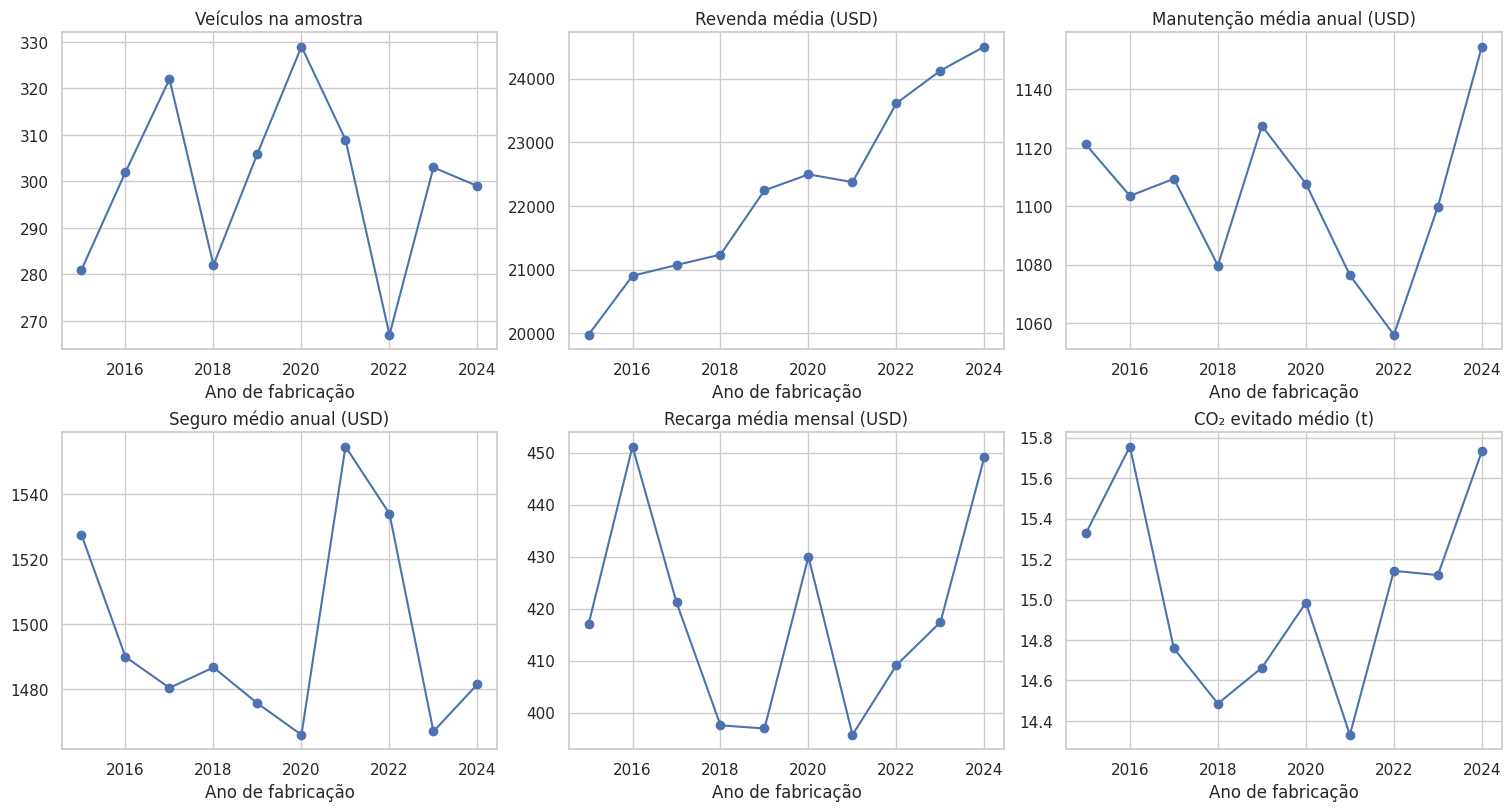

,Média projetada (USD),Limite inferior 95%,Limite superior 95%
2025,24913.28,24090.71,25735.84
2026,25396.20,24533.80,26258.59


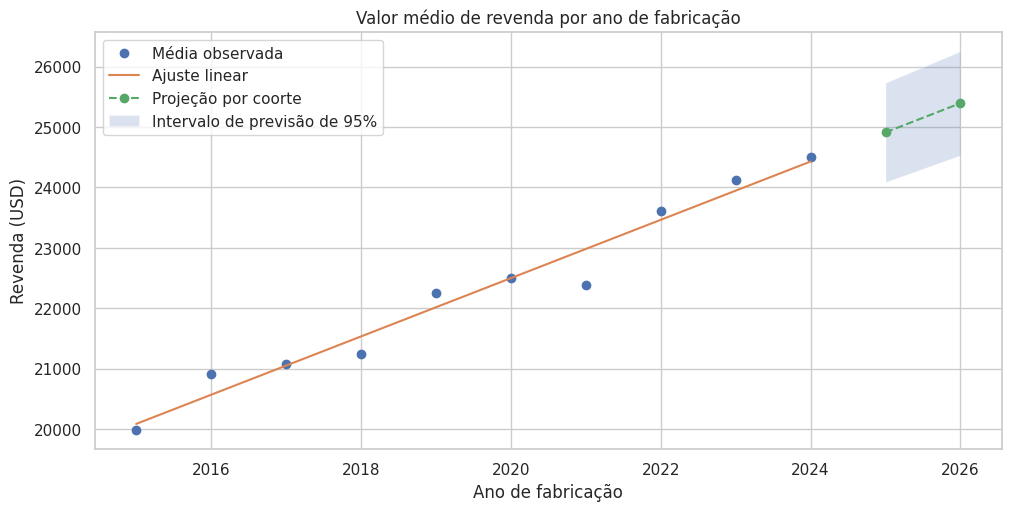

A revenda média passou de **USD 19,978** em 2015 para **USD 24,506** em 2024. O ajuste linear estimou **USD +483 por ano de fabricação**. Nos dois anos reservados para a checagem retrospectiva, o erro médio absoluto foi de USD 307 para a reta e USD 701 ao repetir a última média conhecida. Há somente dez coortes e os intervalos dependem das hipóteses do ajuste linear.

Manutenção média anual (USD) | 2015: 1121.19 USD | 2024: 1154.69 USD | variação: +33.50 USD
Seguro médio anual (USD) | 2015: 1527.49 USD | 2024: 1481.55 USD | variação: -45.94 USD
Recarga média mensal (USD) | 2015: 416.99 USD | 2024: 449.21 USD | variação: +32.21 USD
CO₂ evitado médio (t) | 2015: 15.33 t | 2024: 15.73 t | variação: +0.40 t


In [4]:
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error

anuais = dados.groupby("Year").agg(
    veiculos=("Vehicle_ID", "size"),
    revenda_media=(alvo, "mean"),
    manutencao_media=("Maintenance_Cost_USD", "mean"),
    seguro_medio=("Insurance_Cost_USD", "mean"),
    recarga_media=("Monthly_Charging_Cost_USD", "mean"),
    co2_medio=("CO2_Saved_tons", "mean"),
    co2_total=("CO2_Saved_tons", "sum"),
)
display(anuais.round(2))
fig, eixos = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
indicadores = {
    "veiculos": "Veículos na amostra", "revenda_media": "Revenda média (USD)",
    "manutencao_media": "Manutenção média anual (USD)", "seguro_medio": "Seguro médio anual (USD)",
    "recarga_media": "Recarga média mensal (USD)", "co2_medio": "CO₂ evitado médio (t)",
}
for (coluna, titulo), ax in zip(indicadores.items(), eixos.flat):
    ax.plot(anuais.index, anuais[coluna], marker="o")
    ax.set(title=titulo, xlabel="Ano de fabricação")
plt.show()

origem = anuais.index.min()
anos = anuais.index.to_numpy()
desenho = sm.add_constant(anos - origem, has_constant="add")
revenda = anuais.revenda_media.to_numpy()
validacao = sm.OLS(revenda[:-2], desenho[:-2]).fit()
mae_linear = mean_absolute_error(revenda[-2:], validacao.predict(desenho[-2:]))
mae_constante = mean_absolute_error(revenda[-2:], np.repeat(revenda[-3], 2))
tendencia = sm.OLS(revenda, desenho).fit()
futuros = np.arange(anos[-1] + 1, anos[-1] + 3)
projecao = tendencia.get_prediction(sm.add_constant(futuros - origem, has_constant="add")).summary_frame()
projecao.index = futuros
display(projecao[["mean", "obs_ci_lower", "obs_ci_upper"]].round(2).rename(
    columns={"mean": "Média projetada (USD)", "obs_ci_lower": "Limite inferior 95%",
             "obs_ci_upper": "Limite superior 95%"}
))

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.plot(anos, revenda, "o", label="Média observada")
ax.plot(anos, tendencia.fittedvalues, label="Ajuste linear")
ax.plot(futuros, projecao["mean"], "--o", label="Projeção por coorte")
ax.fill_between(futuros, projecao.obs_ci_lower, projecao.obs_ci_upper, alpha=.2,
                label="Intervalo de previsão de 95%")
ax.set(title="Valor médio de revenda por ano de fabricação",
       xlabel="Ano de fabricação", ylabel="Revenda (USD)")
ax.legend()
plt.show()

display(Markdown(
    f"A revenda média passou de **USD {revenda[0]:,.0f}** em {anos[0]} para "
    f"**USD {revenda[-1]:,.0f}** em {anos[-1]}. O ajuste linear estimou "
    f"**USD {tendencia.params[1]:+,.0f} por ano de fabricação**. "
    f"Nos dois anos reservados para a checagem retrospectiva, o erro médio absoluto "
    f"foi de USD {mae_linear:,.0f} para a reta e USD {mae_constante:,.0f} ao repetir "
    f"a última média conhecida. Há somente dez coortes e os intervalos dependem "
    f"das hipóteses do ajuste linear."
))
for coluna in ["manutencao_media", "seguro_medio", "recarga_media", "co2_medio"]:
    serie = anuais[coluna]
    unidade = "t" if coluna == "co2_medio" else "USD"
    print(f"{indicadores[coluna]} | {anos[0]}: {serie.iloc[0]:.2f} {unidade} | "
          f"{anos[-1]}: {serie.iloc[-1]:.2f} {unidade} | "
          f"variação: {serie.iloc[-1] - serie.iloc[0]:+.2f} {unidade}")

## 3. Modelagem preditiva

O objetivo é estimar o valor de revenda para veículos semelhantes aos da amostra. Reservamos 20% dos registros para teste aleatório. A validação em cinco dobras no treino seleciona o menor MAE. O pré-processamento usa imputação, padronização numérica e one-hot encoding dentro de cada dobra. Excluímos o identificador e o alvo. O teste simula veículos da mesma população e inclui anos já vistos no treino.

,MAE CV (USD),Desvio MAE CV (USD),MAE teste (USD),RMSE teste (USD),R² teste
Modelo,,,,,
Combinação (média),1555.184,29.051,1516.946,1753.166,0.900
Ridge,1559.855,25.043,1530.372,1759.573,0.899
Floresta aleatória,1565.246,39.408,1531.945,1794.047,0.895
Gradient boosting,1576.358,32.501,1528.105,1771.369,0.898
Referência (mediana),4751.657,147.833,4627.543,5548.463,-0.004


**Combinação (média)** venceu pelo MAE de validação. No teste, o erro absoluto médio foi de **USD 1,517**, com **R² de 0.900**.

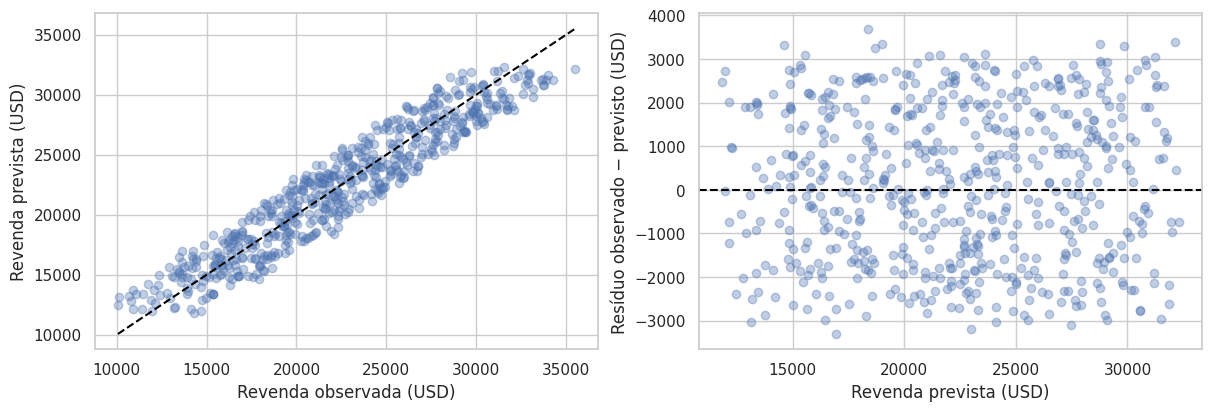

,size,mean
Region,,
Asia,169,1400.94
Australia,144,1475.75
Europe,136,1613.45
North America,151,1599.15


In [5]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = dados.drop(columns=[alvo, "Vehicle_ID"])
y = dados[alvo]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, random_state=42)
num = X.select_dtypes(include="number").columns.tolist()
cat = X.columns.difference(num).tolist()
preparo = ColumnTransformer([
    ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                           ("padronizar", StandardScaler())]), num),
    ("categoricas", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                             ("codificar", OneHotEncoder(handle_unknown="ignore",
                                                        sparse_output=False))]), cat),
])
ridge = Ridge(alpha=10)
floresta = RandomForestRegressor(n_estimators=100, min_samples_leaf=8, random_state=42, n_jobs=2)
boosting = GradientBoostingRegressor(n_estimators=120, max_depth=2, random_state=42)
algoritmos = {
    "Referência (mediana)": DummyRegressor(strategy="median"),
    "Ridge": ridge,
    "Floresta aleatória": floresta,
    "Gradient boosting": boosting,
    "Combinação (média)": VotingRegressor([
        ("ridge", ridge), ("floresta", floresta), ("boosting", boosting)
    ]),
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
pipelines, avaliacoes = {}, []
for nome, modelo in algoritmos.items():
    pipe = Pipeline([("preparo", clone(preparo)), ("regressor", clone(modelo))])
    notas = cross_validate(pipe, X_tr, y_tr, scoring="neg_mean_absolute_error", cv=cv)
    avaliacoes.append({"Modelo": nome, "MAE CV (USD)": -notas["test_score"].mean(),
                       "Desvio MAE CV (USD)": notas["test_score"].std()})
    pipelines[nome] = pipe.fit(X_tr, y_tr)

metricas = pd.DataFrame(avaliacoes).set_index("Modelo").sort_values("MAE CV (USD)")
vencedor = metricas.index[0]
for nome, pipe in pipelines.items():
    previsto = pipe.predict(X_te)
    metricas.loc[nome, "MAE teste (USD)"] = mean_absolute_error(y_te, previsto)
    metricas.loc[nome, "RMSE teste (USD)"] = np.sqrt(mean_squared_error(y_te, previsto))
    metricas.loc[nome, "R² teste"] = r2_score(y_te, previsto)
display(metricas.round(3))
melhor = pipelines[vencedor]
previsto = melhor.predict(X_te)
mae = metricas.loc[vencedor, "MAE teste (USD)"]
r2 = metricas.loc[vencedor, "R² teste"]
display(Markdown(f"**{vencedor}** venceu pelo MAE de validação. No teste, o erro "
                 f"absoluto médio foi de **USD {mae:,.0f}**, com **R² de {r2:.3f}**."))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
eixos[0].scatter(y_te, previsto, alpha=.35)
limites = [min(y_te.min(), previsto.min()), max(y_te.max(), previsto.max())]
eixos[0].plot(limites, limites, "--", color="black")
eixos[0].set(xlabel="Revenda observada (USD)", ylabel="Revenda prevista (USD)")
eixos[1].scatter(previsto, y_te - previsto, alpha=.35)
eixos[1].axhline(0, color="black", linestyle="--")
eixos[1].set(xlabel="Revenda prevista (USD)", ylabel="Resíduo observado − previsto (USD)")
plt.show()

erros = X_te[["Region", "Year"]].assign(erro_absoluto=np.abs(y_te - previsto))
display(erros.groupby("Region").erro_absoluto.agg(["size", "mean"]).round(2))

### Importância das variáveis

Embaralhamos cada coluna original no teste, preservando as demais, e medimos quanto o MAE aumenta. Colunas correlacionadas podem compartilhar sinal, e a importância é específica do modelo e da amostra. O desvio exibido resume a variação entre embaralhamentos.

,Aumento médio do MAE (USD),Desvio (USD)
Battery_Capacity_kWh,4363.18,164.48
Year,586.05,43.77
Energy_Consumption_kWh_per_100km,3.54,1.60
Charging_Time_hr,2.00,0.69
Acceleration_0_100_kmh_sec,1.91,1.15
Range_km,1.75,4.18
Avg_Speed_kmh,0.85,1.30
Region,0.79,0.62
Monthly_Charging_Cost_USD,0.55,1.40
Temperature_C,0.01,1.57


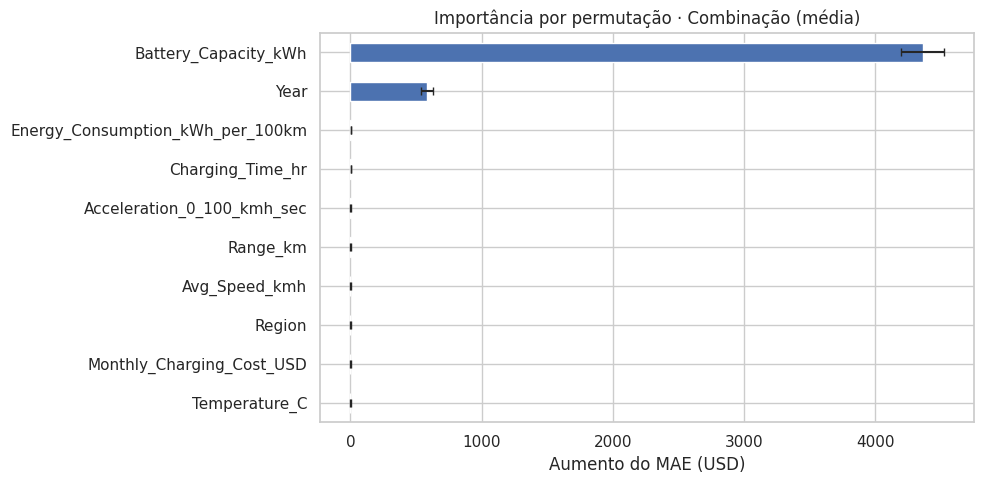

As três variáveis de maior importância nesta avaliação foram `Battery_Capacity_kWh`, `Year`, `Energy_Consumption_kWh_per_100km`.

In [6]:
perm = permutation_importance(melhor, X_te, y_te, scoring="neg_mean_absolute_error",
                              n_repeats=12, random_state=42)
importancia = pd.DataFrame({"Aumento médio do MAE (USD)": perm.importances_mean,
                           "Desvio (USD)": perm.importances_std}, index=X.columns)
ranking = importancia.sort_values("Aumento médio do MAE (USD)", ascending=False)
display(ranking.round(2))
top = ranking.head(10).iloc[::-1]
ax = top["Aumento médio do MAE (USD)"].plot.barh(
    xerr=top["Desvio (USD)"], figsize=(10, 5), capsize=3)
ax.set(title=f"Importância por permutação · {vencedor}", xlabel="Aumento do MAE (USD)")
plt.tight_layout()
plt.show()
display(Markdown("As três variáveis de maior importância nesta avaliação foram "
                 + ", ".join(f"`{nome}`" for nome in ranking.head(3).index) + "."))

### Recomendações para o Negócio

- Padronize o registro de capacidade de bateria, autonomia e ano de fabricação na avaliação de usados. Use a previsão como referência inicial de preço e compare o erro por região, modelo e faixa de preço antes de adotar o processo.
- Valide com transações reais e uma divisão por data de revenda. Registre data, preço, histórico de manutenção, condição da bateria e parâmetros locais para verificar se o desempenho se mantém em veículos de outras coortes.
- Use os agregados de manutenção, recarga e CO₂ para comparar perfis de veículos da amostra. Para medir adoção, acompanhe emplacamentos de elétricos e do mercado total por região e período.